In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import os
import random
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import timm
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, average_precision_score

from LLMIntegration import get_nutritional_info

/Users/vynguyen/opt/anaconda3/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
I0000 00:00:1722011905.339291 2335511 config.cc:230] gRPC experiments enabled: call_status_override_on_cancellation, event_engine_dns, event_engine_listener, http2_stats_fix, monitoring_experiment, pick_first_new, trace_record_callops, work_serializer_clears_time_cache
I0000 00:00:1722011905.370029 2335511 check_gcp_environment_no_op.cc:29] ALTS: Platforms other than Linux and Windows are not supported


**Chicken (100g cooked)**: 165 calories, 31g protein, 0g carbohydrates, 7g fat
**Potato (100g boiled with skin)**: 93 calories, 2g protein, 21g carbohydrates, 0g fat
**Onion (100g)**: 40 calories, 1.1g protein, 9g carbohydrates, 0.1g fat


In [2]:
data = pd.read_csv('./Indian-Food-Dataset/NEW_cuisine123.csv')
data.head(3)

,Dish Name,State,Cuisine,Preparation Time,Description,Diet,Ingredients,Course,len,drop
0,adhirasam,Tamil Nadu,South_Indian,60 mins,Sweet rice flour doughnut,Vegetarian,"Rice flour, jaggery, cardamom, ghee",Dessert,4,1.0
1,aloo_gobi,Punjab,North_Indian,30 mins,Potato and cauliflower curry,Vegetarian,"Potatoes, cauliflower, coriander",Main Course,3,NaN
2,aloo_matar,Punjab,North_Indian,25 mins,Potato and green peas curry,Vegetarian,"Potatoes, green peas, coriander, gravy",Main Course,4,NaN


In [3]:
unique_dishes = data['Dish Name'].nunique()
print("Unique dishses: ", unique_dishes)

Unique dishses:  56


In [4]:
clean_data = data[data['Dish Name'] != 'misi_roti']

# Only keep 'Dish name' is unique identifier and 'Ingredients' is class label
clean_data = clean_data[['Dish Name', 'Ingredients']]

In [5]:
image_folder = './Indian-Food-Dataset/Indian-Food-Images'

# Create a dictionary that maps each unique dish to their corresponding image subfolder
dish_to_images = {}

for dish in clean_data['Dish Name']:
    dish_folder = os.path.join(image_folder, dish)
    if os.path.isdir(dish_folder):
        # Get all image file paths in the dish folderx
        image_files = [os.path.join(dish_folder, img) for img in os.listdir(dish_folder) if img.endswith(('jpg'))]
        
        if image_files:
            dish_to_images[dish] = image_files

            
# print(dish_to_images)

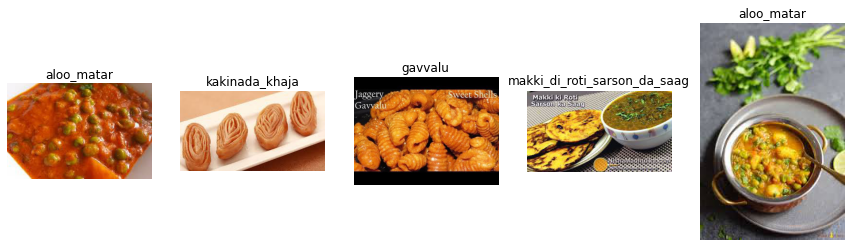

In [6]:
def visualize_images(dish_to_images, num_images):
    dishes = list(dish_to_images.keys())
    plt.figure(figsize=(15, 10))
    
    for i in range(num_images):
        dish = random.choice(dishes)
        image_path = random.choice(dish_to_images[dish])
        image = Image.open(image_path)
        
        plt.subplot(1, num_images, i + 1)
        plt.imshow(image)
        plt.title(dish)
        plt.axis('off')
    
    plt.show()

# Let's see 10 random images with labels
visualize_images(dish_to_images, num_images=5)

# Prepare dataset for model

### Prepare Dishdataset with dish images and their corresponding ingredient labels,

In [7]:
class DishDataset(torch.utils.data.Dataset):
    def __init__(self, dish_to_images, df, transform=None):
        self.dish_to_images = dish_to_images
        self.df = df
        self.transform = transform
        self.label_map ={}
        for idx, label in enumerate(df['Ingredients'].unique()):
            self.label_map[label] = idx
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        dish_name = self.df.iloc[idx]['Dish Name']
        label = self.df.iloc[idx]['Ingredients']
        image_paths = self.dish_to_images[dish_name]
        
        # Choose a random image from the available images for the dish
        image_path = random.choice(image_paths)
        image = Image.open(image_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        label_idx = self.label_map[label]
        return image, label_idx


### Transformation  is applied to each image. It resize images to 224x224 pixels and convert it to a tensor, then normalize the tensor

In [8]:
# Define the data transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


In [9]:
# Create the full dataset
full_dataset = DishDataset(dish_to_images, clean_data, transform=transform)

# Split the dataset into training and testing
train_df, test_df = train_test_split(clean_data, test_size=0.2, random_state=42)

# Create train_dataset and train_loader
train_dataset = DishDataset(dish_to_images, train_df, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Create test_dataset and test_loader
test_dataset = DishDataset(dish_to_images, test_df, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [10]:
print(f"Total images in test dataset: {len(test_dataset)}")
print(f"Total images in train dataset: {len(train_dataset)}")

Total images in test dataset: 11
Total images in train dataset: 44


### Utils

In [11]:
def training_setup(model):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    num_epochs = 10
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=3e-4)
    return model.to(device), num_epochs, device, criterion, optimizer

In [12]:
def train_eval_model(model, epochs, device, criterion, optimizer, train_loader, test_loader, best_val_acc, best_model_file_name ):
    
    tr_losses, val_losses, tr_accs, val_accs = [], [], [], []

    # Training phase
    for epoch in range(epochs):
        model.train()
        epoch_loss, epoch_acc = 0, 0

        for idx, batch in tqdm(enumerate(train_loader), total=len(train_loader)):
            ims, gts = batch
            ims, gts = ims.to(device), gts.to(device)

            optimizer.zero_grad()
            preds = model(ims)
            loss = criterion(preds, gts)
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)

            optimizer.step()

            _, pred_cls = torch.max(preds.data, dim=1)
            epoch_acc += (pred_cls == gts).sum().item()
            epoch_loss += loss.item()

        tr_loss = epoch_loss / len(train_loader)
        tr_acc = epoch_acc / len(train_loader.dataset)
        tr_losses.append(tr_loss)
        tr_accs.append(tr_acc)

        print(f"Epoch {epoch + 1} train process is completed!")
        print(f"Epoch {epoch + 1} train loss -> {tr_loss:.3f}")
        print(f"Epoch {epoch + 1} train accuracy -> {tr_acc:.3f}")

        # Validation phase
        model.eval()
        with torch.no_grad():
            val_epoch_loss, val_epoch_acc = 0, 0
            for idx, batch in enumerate(test_loader):
                ims, gts = batch
                ims, gts = ims.to(device), gts.to(device)

                preds = model(ims)
                loss = criterion(preds, gts)
                _, pred_cls = torch.max(preds.data, dim=1)
                val_epoch_acc += (pred_cls == gts).sum().item()
                val_epoch_loss += loss.item()

            val_acc = val_epoch_acc / len(test_loader.dataset)
            val_loss = val_epoch_loss / len(test_loader)
            val_losses.append(val_loss)
            val_accs.append(val_acc)

            print(f"Epoch {epoch + 1} validation process is completed!")
            print(f"Epoch {epoch + 1} validation loss -> {val_loss:.3f}")
            print(f"Epoch {epoch + 1} validation accuracy -> {val_acc:.3f}")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_model2.pth')
            print(f"New best model saved with validation accuracy: {val_acc:.3f}")
            
    return tr_losses, val_losses, tr_accs, val_accs

In [13]:
def plot_accuracies_losses(train_accs, train_losses, val_accs, val_losses):
    epochs = range(1, len(train_accs) + 1)

    # Plot accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_accs, 'bo-', label='Training Accuracy')
    plt.plot(epochs, val_accs, 'ro-', label='Validation Accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_losses, 'bo-', label='Training Loss')
    plt.plot(epochs, val_losses, 'ro-', label='Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Train model with baseline RexNet150

#### RexNet150

In [18]:
# Train and evaluate model 

num_classes = len(clean_data['Ingredients'].unique())

memory_before = torch.cuda.memory_allocated()
print(f"Memory usage before : {memory_before / 1024 ** 2:.2f} MB")

# Initialize the rexnet_150 model from timm library
model = timm.create_model("rexnet_150", pretrained=True, num_classes=num_classes)

model, epochs, device, criterion, optimizer = training_setup(model)


best_val_acc =  0.273 # from the best prev model
best_model_file_name = 'best_model_2.pth'

# Compute training losses, validation losses, training accuracies, validation accuracies
tr_losses, val_losses, tr_accs, val_accs = train_eval_model(model, epochs, device, criterion, optimizer, train_loader, test_loader, best_val_acc, best_model_file_name)

memory_after = torch.cuda.memory_allocated()
print(f"Memory usage after: {memory_after / 1024 ** 2:.2f} MB")

model_memory_usage = memory_after - memory_before
print(f"Model GPU memory usage: {model_memory_usage / 1024 ** 2:.2f} MB"

100%|█████████████████████████████████████████████| 2/2 [00:19<00:00,  9.98s/it]


Epoch 1 train process is completed!
Epoch 1 train loss -> 4.332
Epoch 1 train accuracy -> 0.023
Epoch 1 validation process is completed!
Epoch 1 validation loss -> 4.428
Epoch 1 validation accuracy -> 0.000


100%|█████████████████████████████████████████████| 2/2 [00:14<00:00,  7.21s/it]


Epoch 2 train process is completed!
Epoch 2 train loss -> 4.117
Epoch 2 train accuracy -> 0.023
Epoch 2 validation process is completed!
Epoch 2 validation loss -> 4.248
Epoch 2 validation accuracy -> 0.000


100%|█████████████████████████████████████████████| 2/2 [00:13<00:00,  6.92s/it]


...

Epoch 8 train process is completed!
Epoch 8 train loss -> 2.438
Epoch 8 train accuracy -> 0.386
Epoch 8 validation process is completed!
Epoch 8 validation loss -> 4.808
Epoch 8 validation accuracy -> 0.000


100%|█████████████████████████████████████████████| 2/2 [00:15<00:00,  7.85s/it]


Epoch 9 train process is completed!
Epoch 9 train loss -> 2.032
Epoch 9 train accuracy -> 0.545
Epoch 9 validation process is completed!
Epoch 9 validation loss -> 5.589
Epoch 9 validation accuracy -> 0.000


100%|█████████████████████████████████████████████| 2/2 [00:16<00:00,  8.21s/it]


Epoch 10 train process is completed!
Epoch 10 train loss -> 2.100
Epoch 10 train accuracy -> 0.477
Epoch 10 validation process is completed!
Epoch 10 validation loss -> 5.292
Epoch 10 validation accuracy -> 0.000


In [19]:
print("Train losses: ", tr_losses)
print("Val losses: ", val_losses)

Train losses:  [4.332242965698242, 4.116615533828735, 3.6432632207870483, 3.5258487462997437, 2.9504363536834717, 2.7164512872695923, 2.6613593101501465, 2.4379299879074097, 2.0317617654800415, 2.1004852056503296]
Val losses:  [4.428369998931885, 4.248106002807617, 4.526223182678223, 4.237471103668213, 4.397589683532715, 4.243377208709717, 4.551998138427734, 4.807835102081299, 5.589108943939209, 5.291785717010498]


In [20]:
# write train losses, validation loss to txt file

filename = 'rexnet150_loss.txt'
with open(filename, 'w') as f:
    f.write("Epoch\tTraining Loss\tValidation Loss\n")
    for epoch, (train_loss, val_loss) in enumerate(zip(tr_losses, val_losses), start=1):
        f.write(f"{epoch}\t{train_loss:.4f}\t{val_loss:.4f}\n")

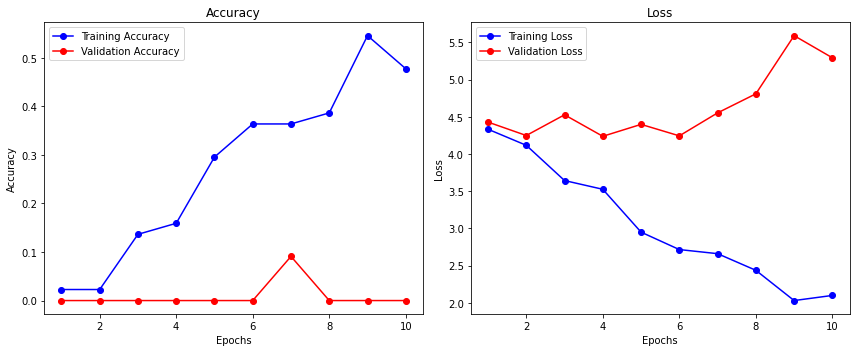

In [21]:
# Plot accuracy and loss

plot_accuracies_losses(tr_accs, tr_losses, val_accs, val_losses)

# Test prediction of best baseline RexNet150 (No transfer learning applied)

In [67]:
# Load the best RexNet150 model that had accuracy of 0.273

num_classes = len(clean_data['Ingredients'].unique())
model_path = 'best_model1.pth'
best_model = timm.create_model('rexnet_150', pretrained=True, num_classes=num_classes)
best_model.load_state_dict(torch.load(model_path))
best_model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.to(device)

RexNet(
  (stem): ConvNormAct(
    (conv): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn): BatchNormAct2d(
      48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
  )
  (features): Sequential(
    (0): LinearBottleneck(
      (conv_dw): ConvNormAct(
        (conv): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=48, bias=False)
        (bn): BatchNormAct2d(
          48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): Identity()
        )
      )
      (act_dw): ReLU6()
      (conv_pwl): ConvNormAct(
        (conv): Conv2d(48, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNormAct2d(
          24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): Identity()
        )
      )
    )
    (1): LinearBottlene

In [69]:
# Collect predictions and  collect  true labels
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        
        outputs = best_model(images)
        probabilities = torch.softmax(outputs, dim=1)
        
        all_predictions.append(probabilities.cpu().numpy())
        all_true_labels.append(labels.cpu().numpy())

# Convert lists to numpy arrays
all_predictions = np.concatenate(all_predictions, axis=0)
all_true_labels = np.concatenate(all_true_labels, axis=0)

In [72]:
# print("all_predictions: ", all_predictions )
# print("all_true_labels: ", all_true_labels)

In [75]:
num_classes = len(clean_data['Ingredients'].unique())
mAP, mAR = calculate_map_mar(all_predictions,all_true_labels, num_classes)

print(f"mAP: {mAP}, mAR: {mAR}")

mAP: 0.2470779220779221, mAR: 0.18968581923127378


In [79]:
dish_to_ingredients = clean_data.set_index('Dish Name')['Ingredients'].to_dict()
def tensor_2_im(tensor):
    tensor = tensor.permute(1, 2, 0).cpu().numpy()  # Change from (C, H, W) to (H, W, C)
    if tensor.shape[2] == 1: 
        tensor = tensor.squeeze(-1)
    tensor = (tensor - tensor.min()) / (tensor.max() - tensor.min())  # Normalize in range [0, 1]
    return tensor

def inference_batch(model, device, test_loader, num_imgs, row, cls_names=None, dish_to_ingredients=None):
    model.eval()
    all_preds = []
    all_images = []
    all_labels = []

    with torch.no_grad():
        for im_batch, label_batch in test_loader:
            im_batch = im_batch.to(device)
            outputs = model(im_batch)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().tolist())
            all_images.extend(im_batch.cpu())
            all_labels.extend(label_batch.cpu().tolist())
            
    # Get nutritional information for all predicted labels
    unique_preds = list(set(all_preds))
    predicted_labels = [cls_names[p] for p in unique_preds]
    nutritional_info = get_nutritional_info(predicted_labels)
    print("nutritional_info: ", nutritional_info)

    # Plot random sample of images with predictions and labels
    plt.figure(figsize=(20, 10))
    indices = [random.randint(0, len(all_images) - 1) for _ in range(num_imgs)]
    for idx, index in enumerate(indices):
        im = all_images[index]
        plt.subplot(row, num_imgs // row, idx + 1)
        plt.imshow(tensor_2_im(im), cmap='gray')
        plt.axis('off')

        pred_idx = all_preds[index]
        pred_name = cls_names[pred_idx]
        true_idx = all_labels[index]
        true_name = cls_names[true_idx]

        # Get ingredients if available
        pred_ingredients = dish_to_ingredients.get(pred_name, "N/A")
        true_ingredients = dish_to_ingredients.get(true_name, "N/A")

        plt.title(f"Pred-> {pred_name} ({pred_ingredients})\nTrue -> {true_name} ({true_ingredients})")

    plt.subplots_adjust(hspace=1)  # Adjust space between rows
    return all_preds, all_labels, nutritional_info

nutritional_info:  **Nutritional Values per 100g:**

* **Gajar ka Halwa:** Calories: 320, Protein: 2.5g, Carbohydrates: 70g, Fat: 10g
* **Aloo Methi:** Calories: 120, Protein: 4g, Carbohydrates: 20g, Fat: 5g
* **Aloo Tikki:** Calories: 250, Protein: 6g, Carbohydrates: 40g, Fat: 12g
* **Bandar Laddu:** Calories: 400, Protein: 10g, Carbohydrates: 60g, Fat: 20g
* **Butter Chicken:** Calories: 280, Protein: 20g, Carbohydrates: 10g, Fat: 20g
* **Lassi:** Calories: 150, Protein: 6g, Carbohydrates: 25g, Fat: 5g
* **Chak Hao Kheer:** Calories: 200, Protein: 5g, Carbohydrates: 35g, Fat: 10g
* **Dum Aloo:** Calories: 180, Protein: 5g, Carbohydrates: 20g, Fat: 10g


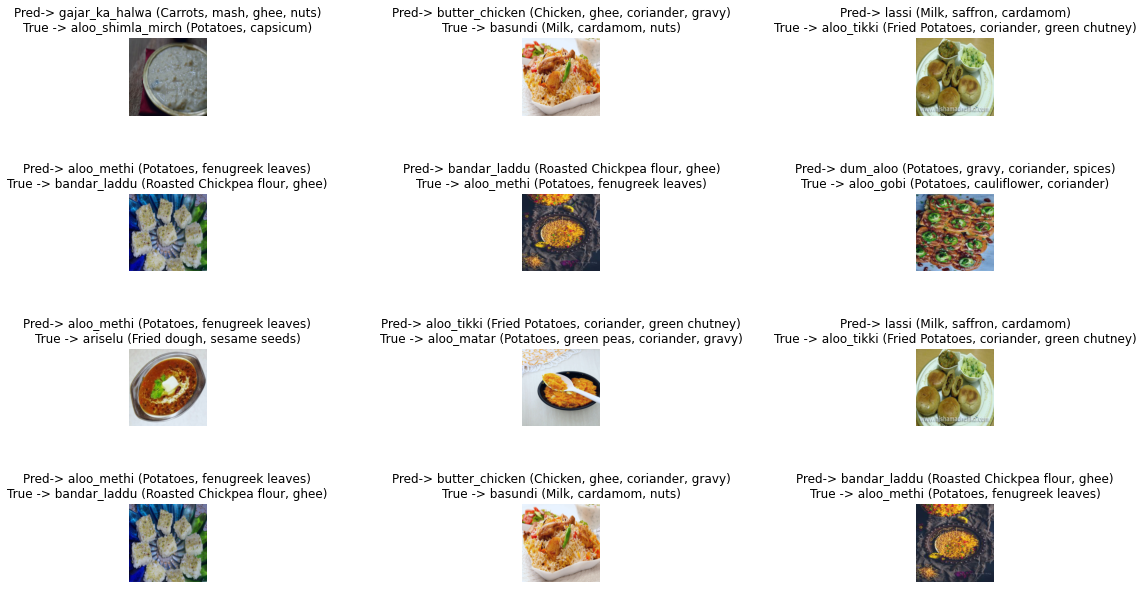

In [80]:
all_preds, all_labels, nutritional_info = inference_batch(
    model=best_model,
    device=device,
    test_loader=test_loader,
    num_imgs = 12,
    row = 4,
    cls_names=list(dish_to_images.keys()), 
    dish_to_ingredients=dish_to_ingredients,
)

# Test prediction of best baseline RexNet150 + Transfer Learning

In [109]:
# Load the best RexNet150 model that had accuracy of 0.273

num_classes = len(clean_data['Ingredients'].unique())
model_path = 'best_model1.pth'
best_model = timm.create_model('rexnet_150', pretrained=True, num_classes=num_classes)
best_model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

In [110]:
# Remove the final classification layer to use the model as a feature extractor
best_model.reset_classifier(0)

In [111]:
def extract_features(model, dataloader):
    model.eval()
    features = []
    labels = []
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            features.append(outputs.cpu())
            labels.append(targets)
    features = torch.cat(features)
    labels = torch.cat(labels)
    return features, labels

In [112]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.to(device)

features, labels = extract_features(best_model, train_loader)

# Save the features and labels for future use
# torch.save(features, 'features.pt')
# torch.save(labels, 'labels.pt')

In [113]:
print(features.shape)
print(labels.shape)

torch.Size([44, 1920])
torch.Size([44])


In [114]:
class SimpleNN(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, 512)
        self.dropout1 = nn.Dropout(p=0.5)  
        self.fc2 = nn.Linear(512, 256)
        self.dropout2 = nn.Dropout(p=0.5) 
        self.fc3 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout1(x)
        x = F.relu(self.fc2(x))
        x = self.dropout2(x)
        x = self.fc3(x)
        return x

In [115]:
# features = torch.load('features.pt')
# labels = torch.load('labels.pt')

In [116]:
feature_dataset = TensorDataset(features, labels)
feature_dataloader = DataLoader(feature_dataset, batch_size=32, shuffle=True)

In [117]:
input_dim = features.shape[1]
num_classes = len(clean_data['Ingredients'].unique())
new_model = SimpleNN(input_dim=input_dim, num_classes=num_classes)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
new_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(new_model.parameters(), lr=1e-3)
epochs = 10

In [118]:
tr_losses, val_losses, tr_accs, val_accs = [], [], [], []
best_val_acc = 0.273
for epoch in range(epochs):
    new_model.train()
    epoch_loss, epoch_acc = 0, 0

    for idx, batch in enumerate(feature_dataloader):
        ims, gts = batch
        ims, gts = ims.to(device), gts.to(device)
        
        optimizer.zero_grad()
        preds = new_model(ims)
        loss = criterion(preds, gts)
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(new_model.parameters(), max_norm=2.0)
        
        optimizer.step()
        
        _, pred_cls = torch.max(preds.data, dim=1)
        epoch_acc += (pred_cls == gts).sum().item()
        epoch_loss += loss.item()
    
    tr_loss = epoch_loss / len(feature_dataloader)
    tr_acc = epoch_acc / len(feature_dataloader.dataset)
    print(" ")
    print(f"Epoch {epoch + 1} train process is completed!")
    print(f"Epoch {epoch + 1} train loss -> {tr_loss:.3f}")
    print(f"Epoch {epoch + 1} train accuracy -> {tr_acc:.3f}")
    tr_losses.append(tr_loss)
    tr_accs.append(tr_acc)

    # Validation phase 
    new_model.eval()
    with torch.no_grad():
        val_epoch_loss, val_epoch_acc = 0, 0
        for idx, batch in enumerate(feature_dataloader): 
            ims, gts = batch
            ims, gts = ims.to(device), gts.to(device)
            
            preds = new_model(ims)
            loss = criterion(preds, gts)
            _, pred_cls = torch.max(preds.data, dim=1)
            val_epoch_acc += (pred_cls == gts).sum().item()
            val_epoch_loss += loss.item()
        
        val_acc = val_epoch_acc / len(feature_dataloader.dataset)
        val_loss = val_epoch_loss / len(feature_dataloader)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        
        print(f"Epoch {epoch + 1} validation process is completed!")
        print(f"Epoch {epoch + 1} validation loss -> {val_loss:.3f}")
        print(f"Epoch {epoch + 1} validation accuracy -> {val_acc:.3f}")
        
    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(new_model.state_dict(), 'best_model_after.pth')
        print(f"New best model saved with validation accuracy: {val_acc:.3f}")

 
Epoch 1 train process is completed!
Epoch 1 train loss -> 3.966
Epoch 1 train accuracy -> 0.000
Epoch 1 validation process is completed!
Epoch 1 validation loss -> 3.893
Epoch 1 validation accuracy -> 0.273
 
Epoch 2 train process is completed!
Epoch 2 train loss -> 3.888
Epoch 2 train accuracy -> 0.091
Epoch 2 validation process is completed!
Epoch 2 validation loss -> 3.784
Epoch 2 validation accuracy -> 0.523
New best model saved with validation accuracy: 0.523
 
Epoch 3 train process is completed!
Epoch 3 train loss -> 3.775
Epoch 3 train accuracy -> 0.182
Epoch 3 validation process is completed!
Epoch 3 validation loss -> 3.670
Epoch 3 validation accuracy -> 0.750
New best model saved with validation accuracy: 0.750
 
Epoch 4 train process is completed!
Epoch 4 train loss -> 3.666
Epoch 4 train accuracy -> 0.318
Epoch 4 validation process is completed!
Epoch 4 validation loss -> 3.480
Epoch 4 validation accuracy -> 0.773
New best model saved with validation accuracy: 0.773
 
Epo

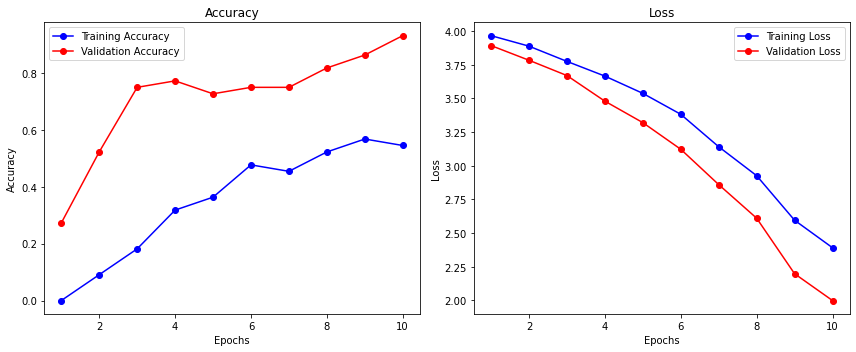

In [119]:
plot_accuracies_losses(tr_accs, tr_losses, val_accs, val_losses)

In [120]:
# best_model_after_transfer_learning, embedded in a simple CNN 
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1) 
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.fc1 = nn.Linear(128 * 7 * 7, 512)  
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 128 * 7 * 7)  # Flatten the tensor
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    
num_classes = len(clean_data['Ingredients'].unique())
new_model = SimpleCNN(num_classes=num_classes).to(device)

# Save the retrained model
torch.save(new_model.state_dict(), 'best_model_after.pth')

# Load the retrained model and perform inference
new_model.load_state_dict(torch.load('best_model_after.pth'))


<All keys matched successfully>

In [121]:
new_model.eval()

SimpleCNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=6272, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=53, bias=True)
)

In [122]:
dish_to_ingredients = clean_data.set_index('Dish Name')['Ingredients'].to_dict()
# dish_to_ingredients 

In [123]:
dish_to_ingredients = clean_data.set_index('Dish Name')['Ingredients'].to_dict()
def tensor_2_im(tensor):
    tensor = tensor.permute(1, 2, 0).cpu().numpy()  # Change from (C, H, W) to (H, W, C)
    if tensor.shape[2] == 1: 
        tensor = tensor.squeeze(-1)
    tensor = (tensor - tensor.min()) / (tensor.max() - tensor.min())  # Normalize in range [0, 1]
    return tensor

def inference_batch(model, device, test_loader, num_imgs, row, cls_names=None, dish_to_ingredients=None):
    model.eval()
    all_preds = []
    all_images = []
    all_labels = []

    with torch.no_grad():
        for im_batch, label_batch in test_loader:
            im_batch = im_batch.to(device)
            outputs = model(im_batch)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().tolist())
            all_images.extend(im_batch.cpu())
            all_labels.extend(label_batch.cpu().tolist())
            
    # Get nutritional information for all predicted labels
    unique_preds = list(set(all_preds))
    predicted_labels = [cls_names[p] for p in unique_preds]
    nutritional_info = get_nutritional_info(predicted_labels)
    print("nutritional_info: ", nutritional_info)

    # Plot random sample of images with predictions and labels
    plt.figure(figsize=(20, 10))
    indices = [random.randint(0, len(all_images) - 1) for _ in range(num_imgs)]
    for idx, index in enumerate(indices):
        im = all_images[index]
        plt.subplot(row, num_imgs // row, idx + 1)
        plt.imshow(tensor_2_im(im), cmap='gray')
        plt.axis('off')

        pred_idx = all_preds[index]
        pred_name = cls_names[pred_idx]
        true_idx = all_labels[index]
        true_name = cls_names[true_idx]

        # Get ingredients if available
        pred_ingredients = dish_to_ingredients.get(pred_name, "N/A")
        true_ingredients = dish_to_ingredients.get(true_name, "N/A")

        plt.title(f"Pred-> {pred_name} ({pred_ingredients})\nTrue -> {true_name} ({true_ingredients})")

    plt.subplots_adjust(hspace=1)  # Adjust space between rows
    return all_preds, all_labels, nutritional_info

nutritional_info:  **Nutritional Information per 100g:**

* **Adhirasam:** Calories: 500, Protein: 3g, Carbohydrates: 80g, Fat: 20g
* **Aloo_shimla_mirch:** Calories: 70, Protein: 2g, Carbohydrates: 12g, Fat: 3g
* **Aloo_tikki:** Calories: 250, Protein: 5g, Carbohydrates: 40g, Fat: 10g
* **Anarsa:** Calories: 450, Protein: 4g, Carbohydrates: 75g, Fat: 15g
* **Basundi:** Calories: 200, Protein: 7g, Carbohydrates: 30g, Fat: 10g
* **Butter_chicken:** Calories: 250, Protein: 20g, Carbohydrates: 15g, Fat: 15g
* **Chak_hao_kheer:** Calories: 200, Protein: 5g, Carbohydrates: 35g, Fat: 10g
* **Cham_cham:** Calories: 350, Protein: 6g, Carbohydrates: 60g, Fat: 15g
* **Chicken_razala:** Calories: 200, Protein: 25g, Carbohydrates: 10g, Fat: 10g
* **Daal_baati_churma:** Calories: 350, Protein: 15g, Carbohydrates: 55g, Fat: 15g
* **Daal_puri:** Calories: 250, Protein: 10g, Carbohydrates: 45g, Fat: 10g
* **Dal_tadka:** Calories: 150, Protein: 12g, Carbohydrates: 25g, Fat: 5g
* **Dum_aloo:** Calories:

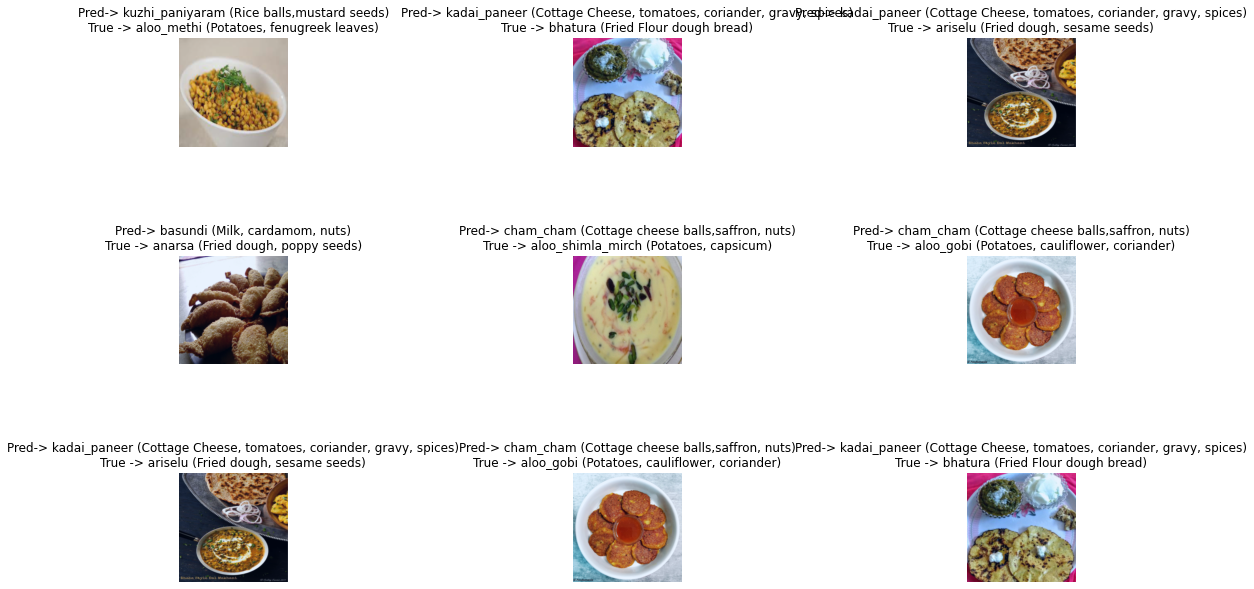

In [125]:
# Example usage
all_preds, all_labels, nutritional_info = inference_batch(
    model=new_model.to(device), 
    device=device, 
    test_loader=test_loader, 
    num_imgs= 9, row=3, 
    cls_names=list(dish_to_images.keys()), 
    dish_to_ingredients=dish_to_ingredients
)

In [126]:
# Collect predictions and  collect  true labels
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        
        outputs = best_model(images)
        probabilities = torch.softmax(outputs, dim=1)
        
        all_predictions.append(probabilities.cpu().numpy())
        all_true_labels.append(labels.cpu().numpy())

# Convert lists to numpy arrays
all_predictions = np.concatenate(all_predictions, axis=0)
all_true_labels = np.concatenate(all_true_labels, axis=0)

In [127]:
num_classes = len(clean_data['Ingredients'].unique())
mAP, mAR = calculate_map_mar(all_predictions,all_true_labels, num_classes)

print(f"mAP: {mAP}, mAR: {mAR}")

mAP: 0.40422405876951334, mAR: 0.2537190082644628
